11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Training data: (60000, 28, 28)
Testing data: (10000, 28, 28)
Preprocessed training data: (60000, 28, 28, 1)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       102,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 121,930 (476.29 KB)

 Trainable params: 121,930 (476.29 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
1543/1543 ━━━━━━━━━━━━━━━━━━━━ 62s 39ms/step - accuracy: 0.9532 - loss: 0.1533 - val_accuracy: 0.9852 - val_loss: 0.0505
Epoch 2/10
1543/1543 ━━━━━━━━━━━━━━━━━━━━ 74s 34ms/step - accuracy: 0.9839 - loss: 0.0513 - val_accuracy: 0.9888 - val_loss: 0.0395
Epoch 3/10
1543/1543 ━━━━━━━━━━━━━━━━━━━━ 49s 32ms/step - accuracy: 0.9888 - loss: 0.0369 - val_accuracy: 0.9902 - val_loss: 0.0387
Epoch 4/10
1543/1543 ━━━━━━━━━━━━━━━━━━━━ 49s 32ms/step - accuracy: 0.9918 - loss: 0.0261 - val_accuracy: 0.9905 - val_loss: 0.0362
Epoch 5/10
1543/1543 ━━━━━━━━━━━━━━━━━━━━ 50s 32ms/step - accuracy: 0.9929 - loss: 0.0207 - val_accuracy: 0.9892 - val_loss: 0.0425
Epoch 6/10
1543/1543 ━━━━━━━━━━━━━━━━━━━━ 48s 31ms/step - accuracy: 0.9950 - loss: 0.0154 - val_accuracy: 0.9903 - val_loss: 0.0346
Epoch 7/10
1543/1543 ━━━━━━━━━━━━━━━━━━━━ 83s 32ms/step - accuracy: 0.9956 - loss: 0.0137 - val_accuracy: 0.9917 - val_loss: 0.0385
Epoch 8/10
1543/1543 ━━━━━━━━━━━━━━━━━━━━ 84s 33ms/step - accuracy: 0.9965 -

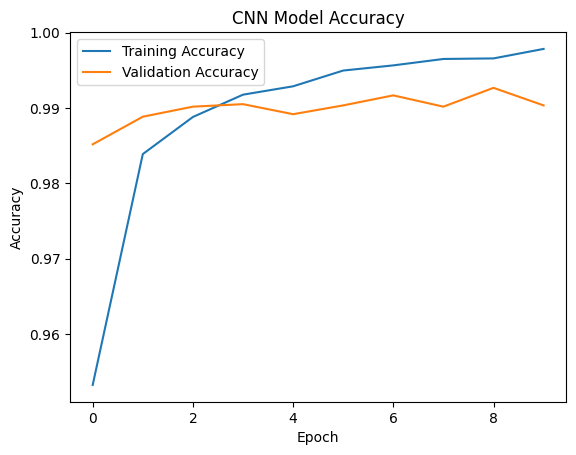

Predicted digit: 9
Actual digit: 9


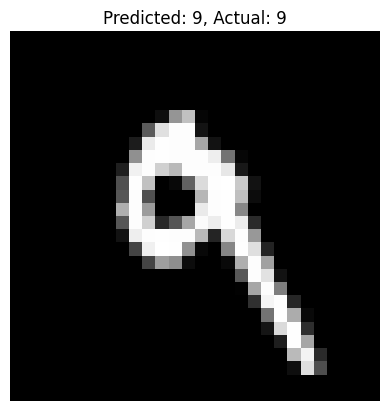

In [ ]:
# Experiment 8: Design and Implement a CNN Model for Digit Recognition

# Step 1: Import libraries
import numpy as np
import matplotlib.pyplot as plt
from keras.layers import Conv2D, Input, MaxPooling2D, Flatten, Dense
from keras.models import Sequential
from keras.datasets import mnist

# Step 2: Load MNIST dataset
(X_train, y_train), (X_test, y_test) = mnist.load_data()

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

# Step 3: Preprocess images
# Normalize pixel values to the range 0 to 1
X_train = X_train.astype('float32') / 255.0
X_test = X_test.astype("float32") / 255.0

# Add channel dimension for grayscale images
X_train = np.expand_dims(X_train, axis=-1)
X_test = np.expand_dims(X_test, axis=-1)

print("Preprocessed training data:", X_train.shape)

# Step 4: Build CNN model
model = Sequential([
    Input(shape=(28, 28, 1)),

    Conv2D(32, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),

    Conv2D(64, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),

    Flatten(),
    Dense(64, activation='relu'),
    Dense(10, activation='softmax')
])

# Step 5: Display model architecture
model.summary()

# Step 6: Compile the model
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Step 7: Train the model
history = model.fit(
    X_train, y_train,
    epochs=10,
    batch_size=35,
    validation_split=0.1
)

# Step 8: Evaluate on unseen test data
test_loss, test_accuracy = model.evaluate(X_test, y_test)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

# Step 9: Plot training and validation accuracy
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('CNN Model Accuracy')
plt.legend()
plt.show()

# Step 10: Predict a sample digit
sample = np.expand_dims(X_test[7], axis=0)

prediction = model.predict(sample, verbose=0)
predicted_digit = np.argmax(prediction)

print("Predicted digit:", predicted_digit)
print("Actual digit:", y_test[7])

# Step 11: Display the test image
plt.imshow(X_test[7].squeeze(), cmap='gray')
plt.title(f"Predicted: {predicted_digit}, Actual: {y_test[7]}")
plt.axis('off')
plt.show()

In [ ]:
# Expt. No. 8 (Manual)
# Title: Design and implement a CNN model for Digit Recognition

import numpy as np
from keras.layers import Conv2D, Input, MaxPooling2D, Flatten, Dense
from keras.models import Sequential
from keras.datasets import mnist

(X_train, y_train), (X_test, y_test) = mnist.load_data()

X_train = X_train.reshape(-1, 28, 28, 1) / 255.0
X_test = X_test.reshape(-1, 28, 28, 1) / 255.0

model = Sequential()

model.add(Input(shape=(28, 28, 1)))
model.add(Conv2D(32, (3, 3), activation='relu'))
model.add(MaxPooling2D((2, 2)))
model.add(Conv2D(64, (3, 3), activation='relu'))
model.add(MaxPooling2D((2, 2)))
model.add(Flatten())
model.add(Dense(64, activation='relu'))
model.add(Dense(10, activation='softmax'))

model.summary()

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.fit(
    X_train,
    y_train,
    epochs=10,
    batch_size=35,
    validation_data=(X_test, y_test)
)

sample = np.expand_dims(X_test[7], axis=0)

prediction = model.predict(sample)

predicted_digit = np.argmax(prediction)

print("Predicted Digit:", predicted_digit)
print("Actual Digit:", y_test[7])


# OUTPUT:
#
# Epoch 1/10
# accuracy: Approximately 0.9002
# loss: Approximately 0.3207
# val_accuracy: Approximately 0.9856
# val_loss: Approximately 0.0457
#
# Epoch 2/10
# accuracy: Approximately 0.9848
# val_accuracy: Approximately 0.9887
#
# Epoch 3/10
# accuracy: Approximately 0.9902
# val_accuracy: Approximately 0.9883
#
# Epoch 4/10
# accuracy: Approximately 0.9927
# val_accuracy: Approximately 0.9899
#
# Epoch 5/10
# accuracy: Approximately 0.9947
# val_accuracy: Approximately 0.9901
#
# Epoch 6/10
# accuracy: Approximately 0.9955
# val_accuracy: Approximately 0.9916
#
# Epoch 7/10
# accuracy: Approximately 0.9972
# val_accuracy: Approximately 0.9918
#
# Epoch 8/10
# accuracy: Approximately 0.9970
# val_accuracy: Approximately 0.9909
#
# Epoch 9/10
# accuracy: Approximately 0.9975
# val_accuracy: Approximately 0.9899
#
# Epoch 10/10
# accuracy: Approximately 0.9979
# val_accuracy: Approximately 0.9902
#
# Predicted Digit: 9
# Actual Digit: 9

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │       102,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 121,930 (476.29 KB)

 Trainable params: 121,930 (476.29 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
1715/1715 ━━━━━━━━━━━━━━━━━━━━ 57s 33ms/step - accuracy: 0.9570 - loss: 0.1424 - val_accuracy: 0.9820 - val_loss: 0.0517
Epoch 2/10
1715/1715 ━━━━━━━━━━━━━━━━━━━━ 82s 33ms/step - accuracy: 0.9855 - loss: 0.0479 - val_accuracy: 0.9879 - val_loss: 0.0349
Epoch 3/10
1715/1715 ━━━━━━━━━━━━━━━━━━━━ 56s 32ms/step - accuracy: 0.9898 - loss: 0.0325 - val_accuracy: 0.9900 - val_loss: 0.0329
Epoch 4/10
1715/1715 ━━━━━━━━━━━━━━━━━━━━ 83s 33ms/step - accuracy: 0.9922 - loss: 0.0245 - val_accuracy: 0.9891 - val_loss: 0.0339
Epoch 5/10
1715/1715 ━━━━━━━━━━━━━━━━━━━━ 81s 33ms/step - accuracy: 0.9938 - loss: 0.0184 - val_accuracy: 0.9893 - val_loss: 0.0320
Epoch 6/10
1715/1715 ━━━━━━━━━━━━━━━━━━━━ 56s 32ms/step - accuracy: 0.9951 - loss: 0.0147 - val_accuracy: 0.9909 - val_loss: 0.0283
Epoch 7/10
1715/1715 ━━━━━━━━━━━━━━━━━━━━ 56s 32ms/step - accuracy: 0.9966 - loss: 0.0110 - val_accuracy: 0.9909 - val_loss: 0.0293
Epoch 8/10
1715/1715 ━━━━━━━━━━━━━━━━━━━━ 82s 32ms/step - accuracy: 0.9968 -